# ResNet Exercise 


In [76]:
# step 1: thư viện cần sử dụng  

import torch
import torch.nn as nn
import os
import numpy as np 
import matplotlib.pyplot as plt
import cv2
import torch.optim as optim
import torch.nn.functional as F
import torch.utils.data as data
import torchvision.transforms as transforms
import torchvision.datasets  as dataset
from torchinfo  import summary
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset

In [77]:
# step 2: gán label cho data set
ROOT = "/kaggle/input/datasets/phthongturing/4muatrongnam/weather-dataset/dataset"
classes = {
    label : class_name
        for label , class_name in enumerate(sorted(os.listdir(ROOT)))
}
classes


{0: 'dew',
 1: 'fogsmog',
 2: 'frost',
 3: 'glaze',
 4: 'hail',
 5: 'lightning',
 6: 'rain',
 7: 'rainbow',
 8: 'rime',
 9: 'sandstorm',
 10: 'snow'}

In [78]:

img_paths = []
labels = []
for label , class_name in classes.items():
    class_dir = os.path.join (ROOT, class_name)

    for img_filname in os.listdir(class_dir): 
        img_path = os.path.join(class_dir , img_filname)
        img_paths.append(img_path)
        labels.append(label)

print("Number of images:", len(img_paths))
print("Number of labels:", len(labels))


print("First image:", img_paths[0])
print("First label:", labels[0])

Number of images: 6862
Number of labels: 6862
First image: /kaggle/input/datasets/phthongturing/4muatrongnam/weather-dataset/dataset/dew/2208.jpg
First label: 0


In [79]:
# step 3: chia train vaol, test
seed = 0
val_size = 0.2
test_size = 0.125
is_shuffle = True
# chia theo SKLEAn 
X_train, X_val, y_train, y_val = train_test_split(
    img_paths , labels,
    test_size= val_size,
    shuffle= is_shuffle,
    random_state= seed,
    stratify=labels
)

X_train, X_test, y_train, y_test = train_test_split(
    X_train,y_train,
    test_size= test_size,
    shuffle= is_shuffle,
    random_state= seed,
    stratify= y_train
)

print(f"Train: {len(X_train)} images")
print(f"Test: {len(X_test)} images")
print(f"Validation: {len(X_val)} images")
print(f"Total: {len(X_train) + len(X_test) + len(X_val)} images")




Train: 4802 images
Test: 687 images
Validation: 1373 images
Total: 6862 images


In [80]:
# STEP 4: CREATE PYTORCH DATASET
class WeatherDataset(Dataset):

    def __init__(self, X, y, transform=None):
        self.transform = transform
        self.img_paths = X
        self.labels = y

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, index):
        img_path = self.img_paths[index]  
        label = self.labels[index]   
        img = cv2.imread(img_path, 1)
        if img is None:
            raise ValueError(f"Cannot read image: {img_path}")
        if self.transform:
            img = self.transform(img)

        return img, self.labels[index]

def transforms(img, img_size=(224, 224)):
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    img = cv2.resize(img, img_size)

    img = torch.tensor(img).permute(2, 0, 1).float()

    img = img / 255.0
    return img


train_dataset = WeatherDataset(
    X_train, y_train,
    transform=transforms
)

val_dataset = WeatherDataset(
    X_val, y_val,
    transform=transforms
)

test_dataset = WeatherDataset(
    X_test, y_test,
    transform=transforms
)


In [81]:
# step 5 create dataloader 
train_batch_size = 512
test_batch_size = 8

train_loader = data.DataLoader(
    dataset= train_dataset,
    batch_size= train_batch_size,
    num_workers= 10,
    shuffle=True
)
val_loader = data.DataLoader(
    dataset= val_dataset,
    batch_size= test_batch_size,
    shuffle= False
)
test_loader = data.DataLoader(
    dataset= test_dataset,
    batch_size= test_batch_size,
    shuffle= False
)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


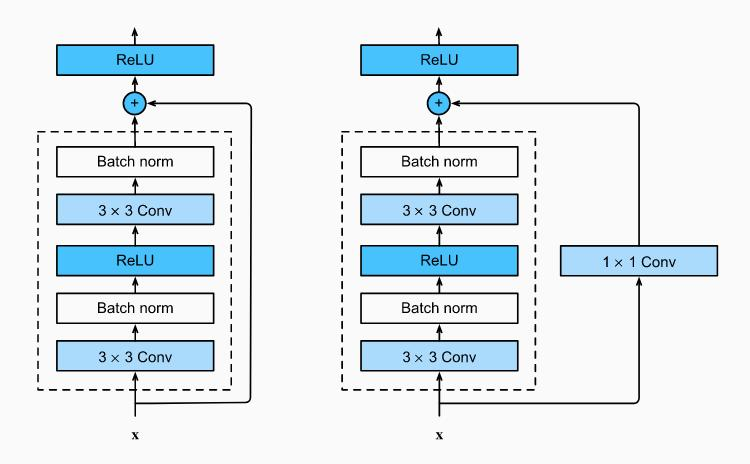

In [82]:
# step 6 buid khối residualblock 

class ResidualBlock(nn.Module):
    def __init__(self, in_channel, out_channel, stride=1):
        super(ResidualBlock, self).__init__()
        # layer 1
        self.conv1 = nn.Conv2d( in_channels=in_channel, out_channels=out_channel, kernel_size=3, stride=stride, padding=1)
        self.batch_norm1 = nn.BatchNorm2d(num_features=out_channel)
        
        # layer 2 
        self.conv2 = nn.Conv2d(in_channels=out_channel, out_channels=out_channel, kernel_size=3, stride=1, padding=1)
        self.batch_norm2 = nn.BatchNorm2d(num_features=out_channel)
        
        # skip connection 
        self.downsample = nn.Sequential() # coi nó như  list rỗng 
        if ((stride != 1) or (in_channel != out_channel)): # đang so sánh trực tiếp in_channel outchannel trên hàm init luôn á
            
            self.downsample = nn.Sequential(
                nn.Conv2d(
                    in_channels=in_channel,
                    out_channels=out_channel,
                    kernel_size=1,
                    stride=stride 
                ),
                nn.BatchNorm2d(num_features=out_channel)
            )
        self.relu = nn.ReLU()

    def forward(self, x):
        shortcut = x.clone()
        output = self.conv1(x)
        output = self.batch_norm1(output)
        output = self.relu(output)

        output = self.conv2(output)
        output =self.batch_norm2(output)
        output = output + self.downsample(shortcut)
        output = self.relu(output)
        return output
    


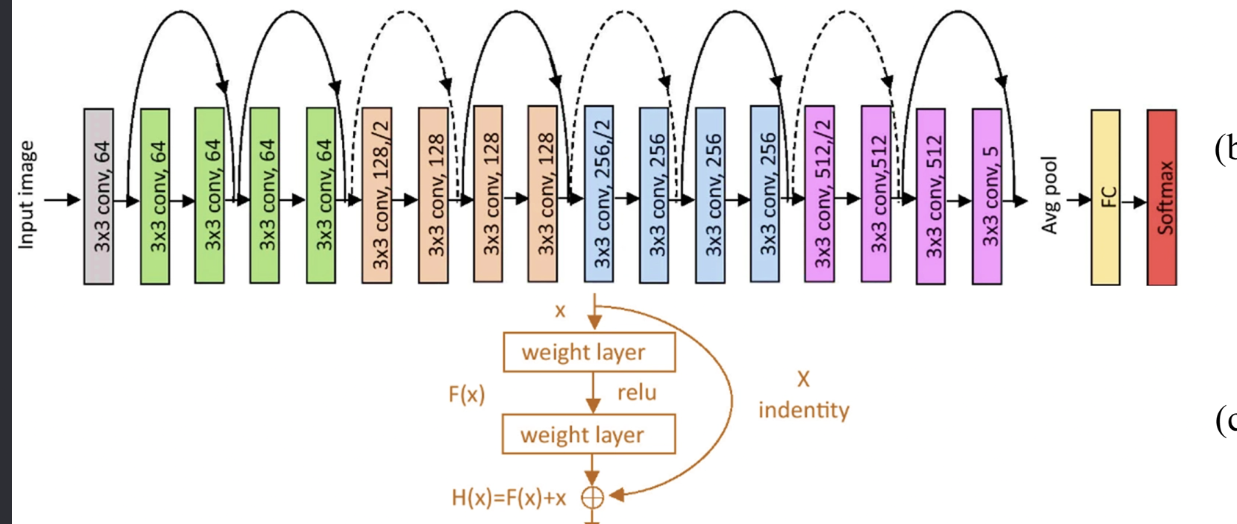

In [83]:
# step Resnet 18 layer
class ResNet(nn.Module):
    def __init__(self, residual_block, n_block_lst, num_class):
        super(ResNet, self).__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3)
        self.batch_norm1 = nn.BatchNorm2d(num_features=64)
        self.relu = nn.ReLU()
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.conv2 = self.create_layer(residual_block, 64, 64, n_blocks=n_block_lst[0], stride=1)
        self.conv3 = self.create_layer(residual_block, 64, 128, n_blocks=n_block_lst[1], stride=2)
        self.conv4 = self.create_layer(residual_block, 128, 256, n_blocks=n_block_lst[2], stride=2)
        self.conv5 = self.create_layer(residual_block, 256, 512, n_blocks=n_block_lst[3], stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d(output_size=1)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(512, num_class)

    def create_layer(self, residual_block, in_channels, out_channels, n_blocks, stride):
        blocks = []
        first_block = residual_block(in_channels, out_channels, stride)
        blocks.append(first_block)
        for _ in range(1, n_blocks):
            block = residual_block(out_channels, out_channels, stride=1)
            blocks.append(block)
        return nn.Sequential(*blocks)

    def forward(self, input):
        output = self.conv1(input)
        output = self.batch_norm1(output)
        output = self.relu(output)
        output = self.maxpool(output)
        output = self.conv2(output)
        output = self.conv3(output)
        output = self.conv4(output)
        output = self.conv5(output)
        output = self.avgpool(output)
        output = self.flatten(output)
        output = self.fc1(output)
        return output
    
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ResNet(
    residual_block=ResidualBlock,
    n_block_lst=[2, 2, 2, 2],
    num_class=len(classes.keys())
).to(device)
output = model(input.to(device))
summary(model)

Layer (type:depth-idx)                   Param #
ResNet                                   --
├─Conv2d: 1-1                            9,472
├─BatchNorm2d: 1-2                       128
├─ReLU: 1-3                              --
├─MaxPool2d: 1-4                         --
├─Sequential: 1-5                        --
│    └─ResidualBlock: 2-1                --
│    │    └─Conv2d: 3-1                  36,928
│    │    └─BatchNorm2d: 3-2             128
│    │    └─Conv2d: 3-3                  36,928
│    │    └─BatchNorm2d: 3-4             128
│    │    └─Sequential: 3-5              --
│    │    └─ReLU: 3-6                    --
│    └─ResidualBlock: 2-2                --
│    │    └─Conv2d: 3-7                  36,928
│    │    └─BatchNorm2d: 3-8             128
│    │    └─Conv2d: 3-9                  36,928
│    │    └─BatchNorm2d: 3-10            128
│    │    └─Sequential: 3-11             --
│    │    └─ReLU: 3-12                   --
├─Sequential: 1-6                        --
│  

In [84]:
# Dựng hàm đánh giá model tính loss acc 
def evaluate(model, dataloader, criterion, device):
    model.eval()
    correct = 0
    total = 0
    losses = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            losses.append(loss.item())
            _, predicted = torch.max(outputs.data, dim= 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    loss = sum(losses) / len(losses)
    acc = correct / total

    return loss, acc

![Screenshot 2026-11-27 124514_edited.png](<attachment:Screenshot 2026-11-27 124514_edited.png>)
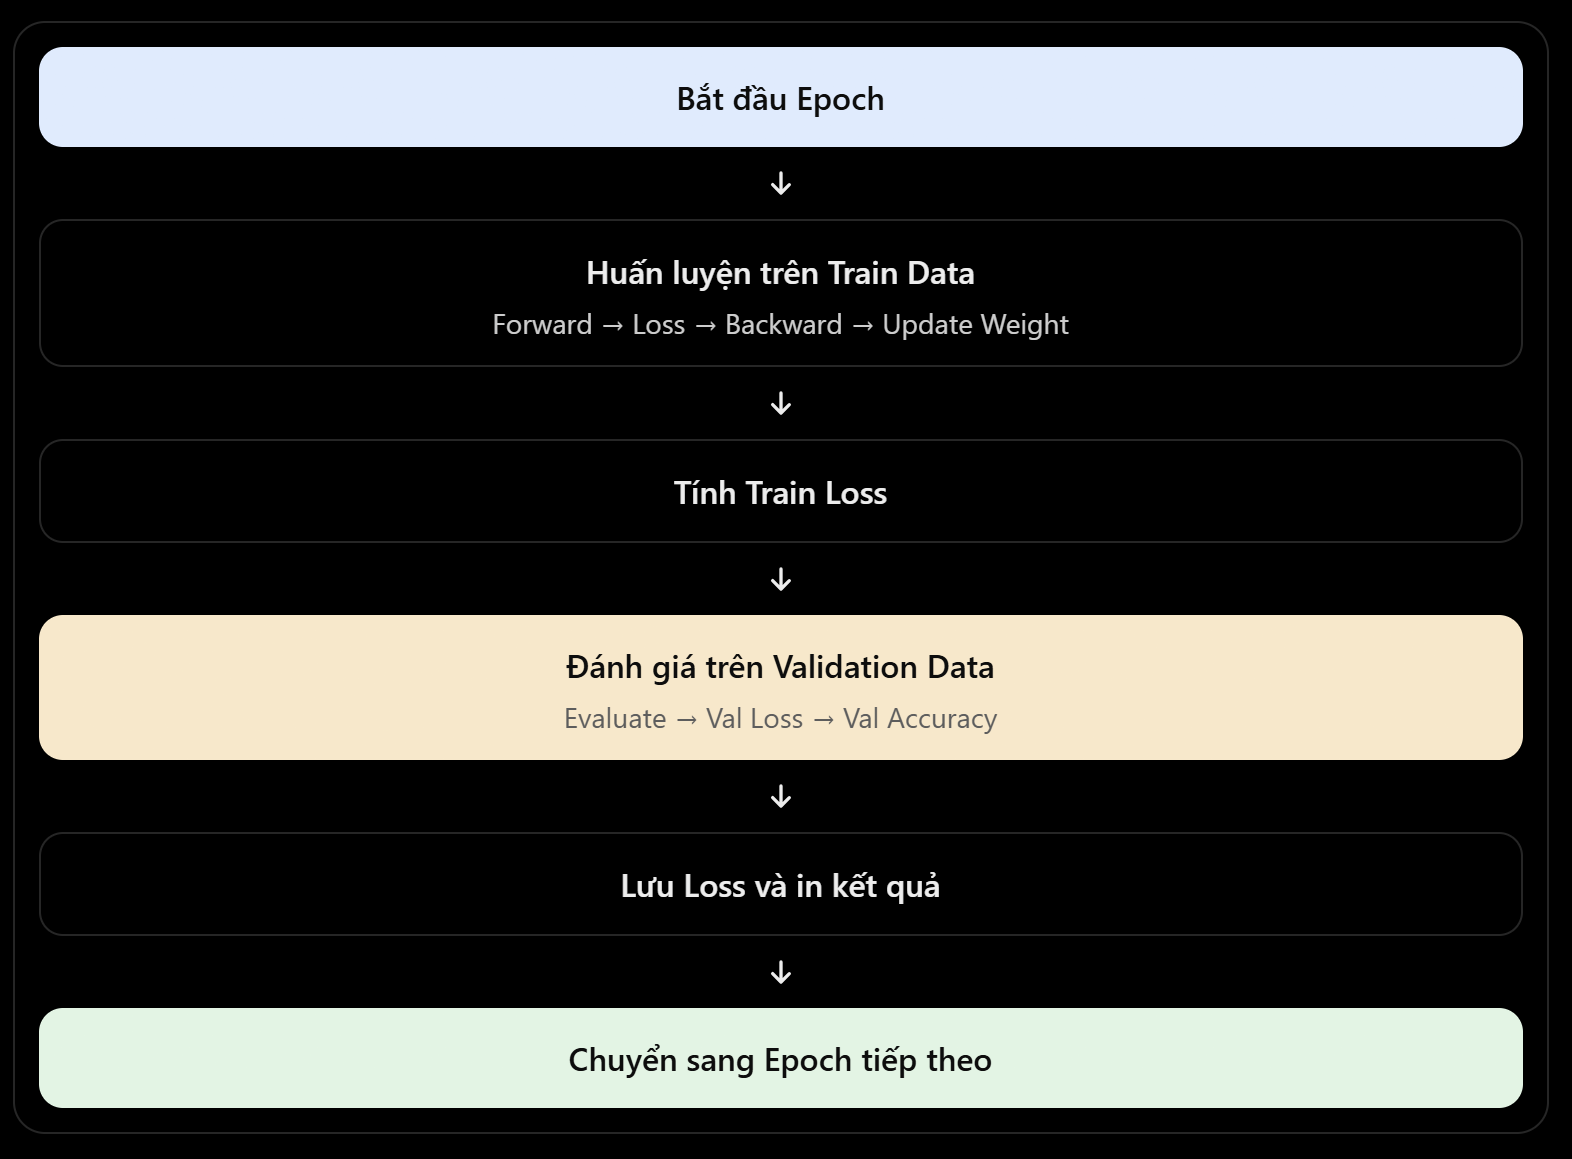

In [85]:
def fit(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs
):
    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        batch_train_losses = []

        model.train()

        for idx, (inputs, labels) in enumerate(train_loader):
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            batch_train_losses.append(loss.item())

        train_loss = sum(batch_train_losses) / len(batch_train_losses)
        train_losses.append(train_loss)

        val_loss, val_acc = evaluate(
            model,
            val_loader,
            criterion,
            device
        )

        val_losses.append(val_loss)

        print(
            f'EPOCH {epoch + 1}: '
            f'Train loss: {train_loss:.4f} '
            f'Val loss: {val_loss:.4f}'
        )

    return train_losses, val_losses

In [86]:
# siêu tham số 
lr = 1e-3
epochs =50
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(params= model.parameters(), lr=lr)


In [87]:
train_losses, val_losses = fit(
    model= model,
    train_loader= train_loader,
    val_loader= val_loader,
    criterion= criterion,
    optimizer= optimizer,
    device=device,
    epochs= epochs 
)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


EPOCH 1: Train loss: 1.9930 Val loss: 5.9522
EPOCH 2: Train loss: 1.2707 Val loss: 10.5825
EPOCH 3: Train loss: 1.1768 Val loss: 9.2145
EPOCH 4: Train loss: 1.0873 Val loss: 6.9477
EPOCH 5: Train loss: 1.0577 Val loss: 6.9924
EPOCH 6: Train loss: 0.9806 Val loss: 5.7389
EPOCH 7: Train loss: 0.9632 Val loss: 5.0051
EPOCH 8: Train loss: 0.9352 Val loss: 3.3898
EPOCH 9: Train loss: 0.8800 Val loss: 1.8476
EPOCH 10: Train loss: 0.8242 Val loss: 1.4870
EPOCH 11: Train loss: 0.7910 Val loss: 1.5378
EPOCH 12: Train loss: 0.7614 Val loss: 1.6301
EPOCH 13: Train loss: 0.7348 Val loss: 1.3091
EPOCH 14: Train loss: 0.6923 Val loss: 1.4325
EPOCH 15: Train loss: 0.7152 Val loss: 1.0424
EPOCH 16: Train loss: 0.6770 Val loss: 1.4547
EPOCH 17: Train loss: 0.6350 Val loss: 1.9183
EPOCH 18: Train loss: 0.6361 Val loss: 1.4155
EPOCH 19: Train loss: 0.5977 Val loss: 1.5744
EPOCH 20: Train loss: 0.6020 Val loss: 1.1467
EPOCH 21: Train loss: 0.5982 Val loss: 1.5272
EPOCH 22: Train loss: 0.5335 Val loss: 1.4

In [88]:
val_loss, val_acc = evaluate(
    model,
    val_loader,
    criterion,
    device
)

test_loss, test_acc = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print('Evaluation on val/test dataset')
print('Val accuracy: ', val_acc)
print('Test accuracy: ', test_acc)

Evaluation on val/test dataset
Val accuracy:  0.7312454479242535
Test accuracy:  0.7540029112081513


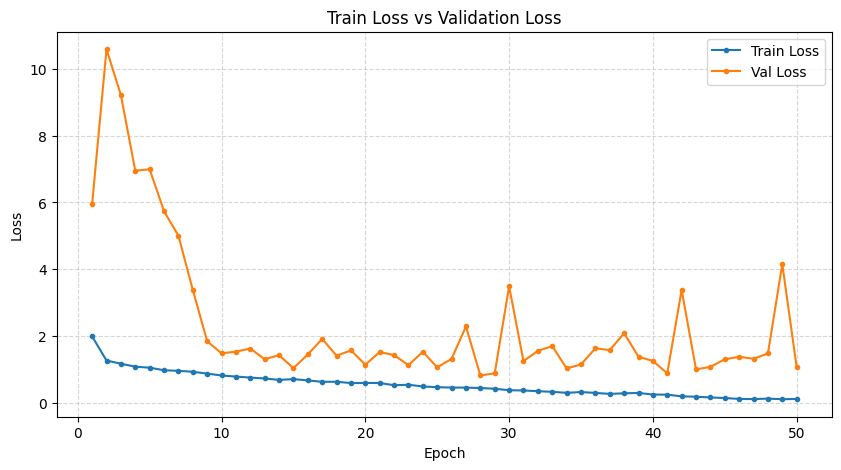

In [89]:

epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs_range, train_losses, label="Train Loss", marker="o", markersize=3)
plt.plot(epochs_range, val_losses, label="Val Loss", marker="o", markersize=3)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train Loss vs Validation Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()